# Single-stock risk report
Prabhutosh Kumar · adjusted-price analysis · daily log returns

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/prabhu/PythonProjects/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Prabhutosh_Kumar/data/data.db"


In [3]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import (load_stock, calculate_returns, calculate_volatility,
                      calculate_max_drawdown, calculate_sharpe_ratio, metrics, plot_report)
frame = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(frame)} trading days")
print(f"Actual observations: {frame.index.min().date()} to {frame.index.max().date()}")
display(frame.head())
display(frame.tail())
if len(frame) < 21:
    print("Insufficient history for 20 returns: rolling volatility is unavailable.")
if len(frame) < 50:
    print("Insufficient history for a 50-day moving average.")
print("Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.")

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539,AAPL,AAPL,11832,,0,0.998866
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445,AAPL,AAPL,11833,,0,0.998868
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785,AAPL,AAPL,11834,,0,0.998826
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",11835,,0,0.998869
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912,AAPL,AAPL,11836,,0,0.998832


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,AAPL,AAPL,11937,,0,1.0
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,AAPL,AAPL,11938,,0,1.0
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,AAPL,AAPL,11939,,0,1.0
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,AAPL,AAPL,11940,,0,1.0
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,AAPL,AAPL,11941,,0,1.0


Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.


## Risk measures
All report returns use adjusted close. Rolling volatility uses 20 log returns and sample standard deviation, annualized by √252. Warm-up gaps are preserved. Sharpe uses the course approximation `(mean log return × 252 − 0.02)/(sample std × √252)`; undefined or zero volatility displays N/A. Drawdown can recover; its minimum is maximum drawdown.

Price segments use mean rolling volatility as a retrospective threshold (red above, green at/below, gray unavailable). Comparisons across stocks with different actual histories are descriptive, not like-for-like performance rankings.

,adj_close,log_return,rolling_volatility,drawdown
ts,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856
2024-10-15,233.85,0.010964,0.243942,-0.002984
2024-10-16,231.78,-0.008891,0.241973,-0.011810
2024-10-17,232.15,0.001595,0.206097,-0.010232
2024-10-18,235.00,0.012202,0.209521,0.000000


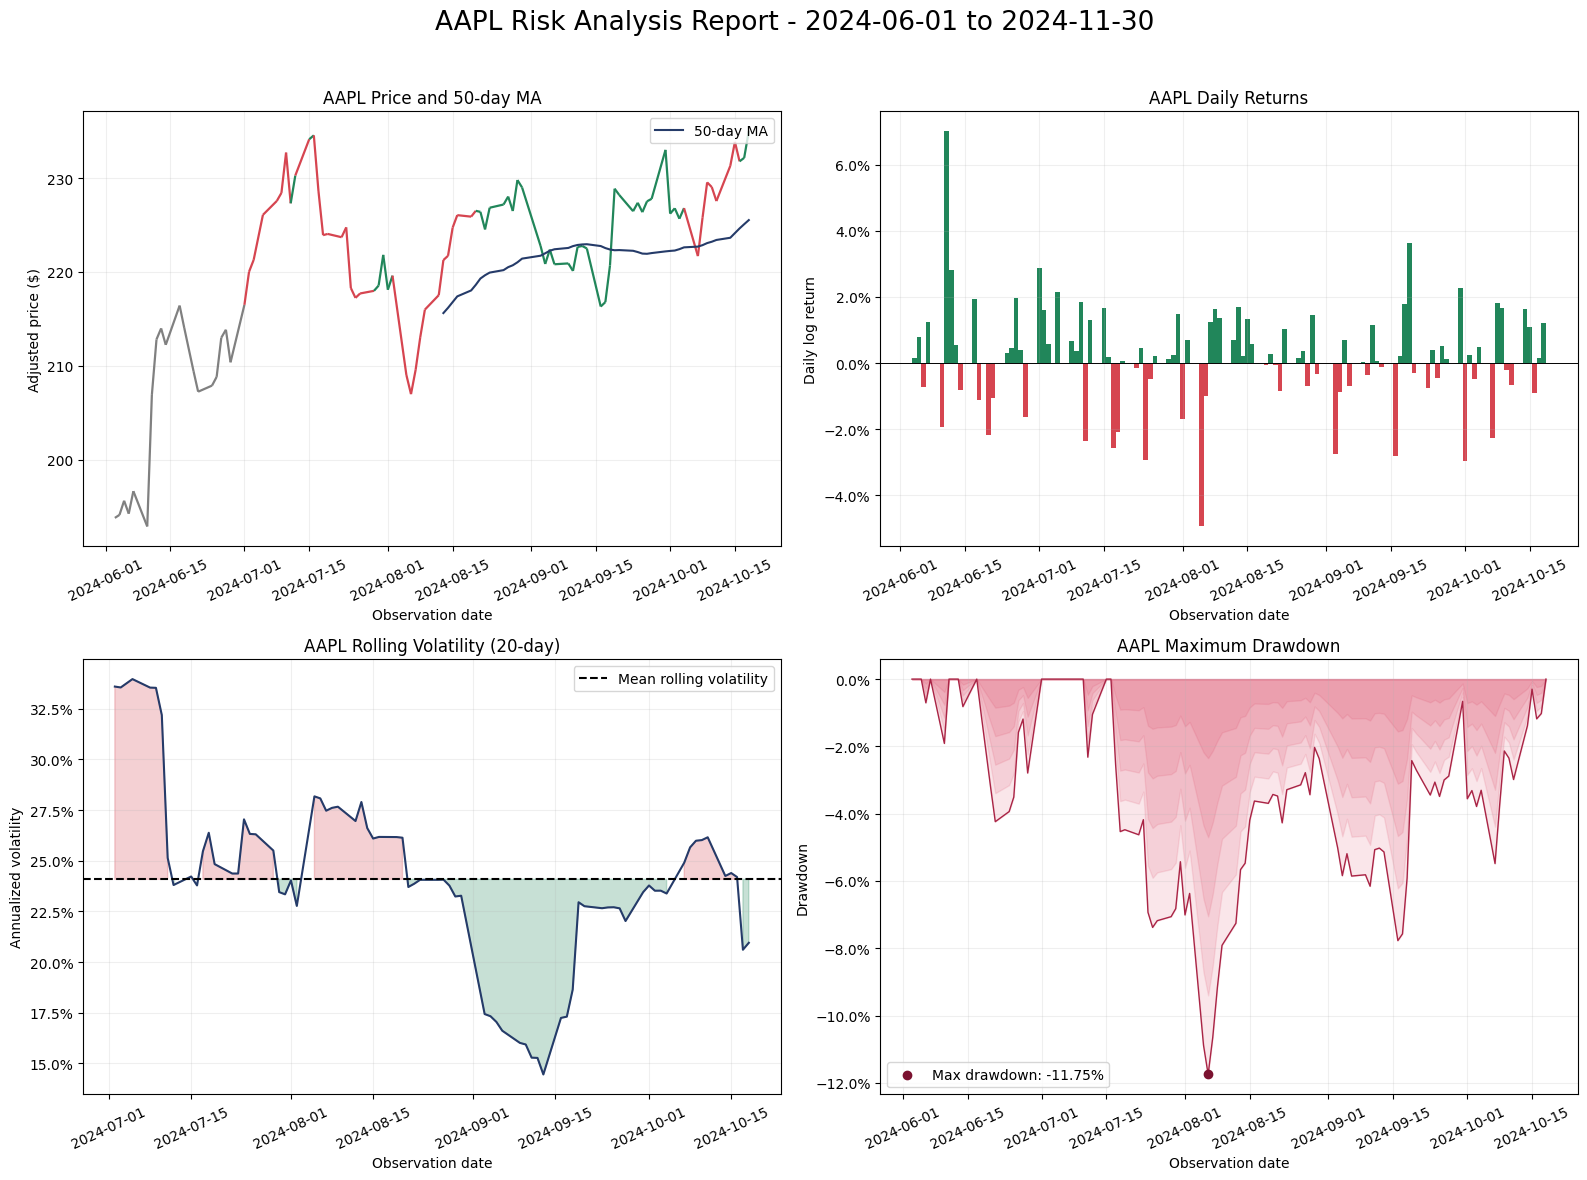

In [4]:
frame["log_return"] = calculate_returns(frame.adj_close)
frame["rolling_volatility"] = calculate_volatility(frame.log_return)
frame["drawdown"] = calculate_max_drawdown(frame.adj_close)
summary = metrics(frame)
display(frame[["adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())
figure = plot_report(frame, ticker, start_date, end_date)
plt.show()
plt.close(figure)

## Summary
Total return is the endpoint price ratio minus one. Annualized return compounds log returns using 252/n. Whole-period annualized volatility differs from the mean rolling volatility used in the portfolio scatter. Best/worst days and up/down averages are log returns. Positive days include zero-return days in the denominator; empty subsets show N/A.

In [5]:
labels = {"total_return": "Total Return", "annualized_return": "Annualized Return",
          "annualized_volatility": "Annualized Volatility", "sharpe_ratio": "Sharpe Ratio",
          "max_drawdown": "Maximum Drawdown", "best_day": "Best Day", "worst_day": "Worst Day",
          "positive_days": "Positive Days", "average_up_day": "Average Up Day", "average_down_day": "Average Down Day"}
rows = []
for key, label in labels.items():
    value = summary[key]
    formatted = "N/A" if not np.isfinite(value) else (f"{value:.2f}" if key == "sharpe_ratio" else f"{value:+.2%}")
    rows.append({"Metric": label, "Value": formatted})
display(pd.DataFrame(rows).set_index("Metric"))

,Value
Metric,
Total Return,+21.25%
Annualized Return,+65.84%
Annualized Volatility,+25.45%
Sharpe Ratio,1.91
Maximum Drawdown,-11.75%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,+62.50%
Average Up Day,+1.09%


In [6]:
# Named machine-readable result collected only after successful execution.
output = {key: (float(value) if np.isfinite(value) else None) for key, value in summary.items()}
output.update(ticker=ticker, actual_start=str(frame.index.min().date()),
              actual_end=str(frame.index.max().date()), observations=len(frame))
print("HW2_SUMMARY=" + json.dumps(output, allow_nan=False))

HW2_SUMMARY={"total_return": 0.21252773334709252, "annualized_return": 0.6584052421995118, "annualized_volatility": 0.2545456034304724, "sharpe_ratio": 1.9087206244573933, "max_drawdown": -0.11750159880622468, "best_day": 0.07011199619962621, "worst_day": -0.04937546360551046, "positive_days": 0.625, "average_up_day": 0.01090377723415163, "average_down_day": -0.01281998382271097, "avg_daily_return": 0.002007366837828156, "avg_volatility": 0.240840098800071, "ticker": "AAPL", "actual_start": "2024-06-03", "actual_end": "2024-10-18", "observations": 97}
